# Proyecto ML: Predicción de la concentración del alumno en sesiones particulares con tutores inteligentes

**Autora:** Paula Lull Rios

1. Cargamos el Dataset

In [2]:
import pandas as pd
import os 

# Ruta de datos
b = r"..\data\raw"

# Nombre exacto del archivo principal 
nombre_archivo = "affect_features_and_labels_folded_all_timesteps.csv"
ruta_completa = os.path.join(b, nombre_archivo)

# Cargamos el archivo en un DataFrame principal y miramos su shape e info
df = pd.read_csv(ruta_completa, low_memory=False)


print("Dimensiones del DataFrame:", df.shape)


Dimensiones del DataFrame: (48556, 117)


2. Exploración y decisión sobre la columna target


In [3]:
# Lista de posibles columnas de targets que aparecen en las columnas
columnas_objetivo = [
    'frustration', 'frustration_1', 'frustration_2', 'frustration_3',
    'boredom', 'boredom_1', 'boredom_2', 'boredom_3',
    'confusion', 'confusion_1', 'confusion_2', 'confusion_3'
]

# Vemos cuántos valores NO nulos tiene cada una
for col in columnas_objetivo:
    if col in df.columns:
        validos = df[col].notna().sum()
        print(f"Columna '{col}': {validos} registros válidos (no nulos)")

Columna 'frustration': 3111 registros válidos (no nulos)
Columna 'frustration_1': 748 registros válidos (no nulos)
Columna 'frustration_2': 599 registros válidos (no nulos)
Columna 'frustration_3': 1764 registros válidos (no nulos)
Columna 'boredom': 3111 registros válidos (no nulos)
Columna 'boredom_1': 748 registros válidos (no nulos)
Columna 'boredom_2': 599 registros válidos (no nulos)
Columna 'boredom_3': 1764 registros válidos (no nulos)
Columna 'confusion': 3111 registros válidos (no nulos)
Columna 'confusion_1': 748 registros válidos (no nulos)
Columna 'confusion_2': 599 registros válidos (no nulos)
Columna 'confusion_3': 1764 registros válidos (no nulos)


In [4]:
# Emociones escogidas para el target:
emo = ["confusion", "concentration", "boredom", "frustration"]
# Eliminamos las filas que tengan nulos en las 4 emos
df_emo = df.dropna(subset=emo, how="all")
# Escogemos las filas que tengan 1 en una de las 4 emociones
df_multi = df_emo[df_emo[emo].sum(axis=1) == 1].copy() 
# Creamos la col target, en la que escribimos la emocion con valor 1 de las 4 emos 
df_multi["target"] = df_multi[emo].idxmax(axis=1)
print(df_multi["target"].value_counts(normalize=True))

target
concentration    0.825089
boredom          0.099580
confusion        0.039121
frustration      0.036211
Name: proportion, dtype: float64


En este caso, ante el fuerte desbalanceo, mas adelante convertiremos el target en una variable binaria, centrada en clasificar si el alumno está concentrado o no. De esta manera pretendemos mejorar la capacidad de predicción del modelo reduciendo el ruido que podían generar clases tan poco representadas (aburrimiento, frustración y confusión)

A continuación exploramos nulos y estadísticas generales de las numéricas, donde vemos como ningun mínimo es menor que 0 y algunas columnas parecen ya estandarizadas.

In [5]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df_multi.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
rowid,288166.476560,111028.040765,854.000,455220.00000
clip_id,22256.405755,12687.631282,38.000,43978.00000
clip_sequence,411.211445,205.521466,1.000,766.00000
confusion,0.039121,0.193913,0.000,1.00000
concentration,0.825089,0.379952,0.000,1.00000
boredom,0.099580,0.299487,0.000,1.00000
frustration,0.036211,0.186844,0.000,1.00000
on_task,0.816492,0.387175,0.000,1.00000
off_task,0.183508,0.387175,0.000,1.00000
fold,4.120595,2.942529,0.000,9.00000


In [6]:
df_multi.dtypes

rowid                              int64
clip_id                            int64
clip_sequence                    float64
confusion                        float64
concentration                    float64
boredom                          float64
frustration                      float64
on_task                          float64
off_task                         float64
fold                               int64
user_id                            int64
clip_sequence_id                   int64
avg_attemptCount                 float64
avg_bottomHint                   float64
avg_correct                      float64
avg_frIsHelpRequest              float64
avg_frPast5HelpRequest           float64
avg_frPast5WrongCount            float64
avg_frPast8HelpRequest           float64
avg_frPast8WrongCount            float64
avg_frWorkingInSchool            float64
avg_hint                         float64
avg_hintCount                    float64
avg_hintTotal                    float64
avg_original    

In [7]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Contamos los valores nulos por columna 
nulos_por_columna = df_multi.isnull().sum()

# Filtrar solo las columnas que tienen al menos 1 nulo 
nulos_filtrados = nulos_por_columna[nulos_por_columna > 0]

print("--- Conteo de valores nulos por columna ---")
print(nulos_filtrados)

--- Conteo de valores nulos por columna ---
on_task             995
off_task            995
confusion_1        2356
concentration_1    2356
boredom_1          2356
frustration_1      2356
confusion_2        2498
concentration_2    2498
boredom_2          2498
frustration_2      2498
confusion_3        1332
concentration_3    1332
boredom_3          1332
frustration_3      1332
dtype: int64


Definimos finalmente el DataFrame con el que trabajaremos y hacemos la división en train y test 

In [8]:
emo = ["confusion", "concentration", "boredom", "frustration"]
ids       = ["rowid", "clip_id", "clip_sequence", "fold", "user_id", "clip_sequence_id"]
targets   = emo + ["on_task", "off_task"]
basura   = [f"{e}_{k}" for e in emo for k in (1, 2, 3)]
contexto  = ["urbanicity"]
features  = [c for c in df_emo.columns if c.startswith(("avg_", "max_", "min_", "sum_"))]

quitar = ["rowid", "clip_id", "clip_sequence", "fold", "clip_sequence_id"]   # ids que no usaremos
quitar += emo + ["on_task", "off_task"]                                      # targets originales
quitar += basura                                                           # las 12 columnas basura

df_modelo = df_multi.drop(columns=quitar)
print(df_modelo.shape) 

(3093, 95)


In [9]:
y = df_modelo["target"]
groups = df_modelo["user_id"]   # columna que usaremos para agrupar a los alumnos
X = df_modelo.drop(columns=["target", "user_id"])

In [10]:
# Realizamos la división train test con sgkf para que no separe a un mismo alumno en diferntes folds
from sklearn.model_selection import StratifiedGroupKFold

# hacemos 5 folds, y next deja el primero a test (el 20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = groups.iloc[idx_train], groups.iloc[idx_test]

print(X_train.shape, X_test.shape)
print("alumnos en común:", len(set(g_train) & set(g_test)))      # debe ser 0
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


(2474, 93) (619, 93)
alumnos en común: 0
target
concentration    0.824980
boredom          0.099838
confusion        0.039208
frustration      0.035974
Name: proportion, dtype: float64
target
concentration    0.825525
boredom          0.098546
confusion        0.038772
frustration      0.037157
Name: proportion, dtype: float64


Observamos, de las 93 columnas, si existen algunas constantes que podamos eliminar

In [11]:
n_valores = X_train.nunique()
constantes= n_valores[n_valores==1].index.tolist()
constantes

['avg_timeSinceSkill',
 'max_timeSinceSkill',
 'min_timeSinceSkill',
 'sum_timeSinceSkill']

In [12]:
import numpy as np
X_train = X_train.drop(columns=constantes)
X_test  = X_test.drop(columns=constantes)  
#     
# Miramos la correlación absoluta entre todas las parejas de columnas
corr = X_train.corr().abs()
# Nos quedamos con una sola mitad de la tabla, para no contar cada pareja dos veces
mitad = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Lista de parejas, de más a menos correlacionadas
pares = mitad.stack().sort_values(ascending=False)
altos = pares[pares > 0.95]

print(len(altos), "parejas con correlación > 0.95")
print(altos)

31 parejas con correlación > 0.95
avg_totalFrAttempted           max_totalFrAttempted             0.999931
                               min_totalFrAttempted             0.999930
max_totalFrAttempted           min_totalFrAttempted             0.999722
sum_frPast5WrongCount          sum_frPast8WrongCount            0.998650
max_frPast5WrongCount          max_frPast8WrongCount            0.998290
max_frPast5HelpRequest         max_frPast8HelpRequest           0.998041
sum_frPast5HelpRequest         sum_frPast8HelpRequest           0.997935
max_timeTaken                  sum_timeTaken                    0.997722
avg_frPast5WrongCount          avg_frPast8WrongCount            0.996681
min_frPast5WrongCount          min_frPast8WrongCount            0.995744
avg_frWorkingInSchool          min_frWorkingInSchool            0.990609
                               max_frWorkingInSchool            0.989852
avg_frPast5HelpRequest         avg_frPast8HelpRequest           0.988532
avg_totalFrTimeOn

22 variables base: ['attemptCount', 'bottomHint', 'correct', 'frIsHelpRequest', 'frPast5HelpRequest', 'frPast5WrongCount', 'frPast8HelpRequest', 'frPast8WrongCount', 'frWorkingInSchool', 'hint', 'hintCount', 'hintTotal', 'original', 'past8BottomOut', 'scaffold', 'stlHintUsed', 'timeTaken', 'totalFrAttempted', 'totalFrPastWrongCount', 'totalFrPercentPastWrong', 'totalFrSkillOpportunities', 'totalFrTimeOnSkill']


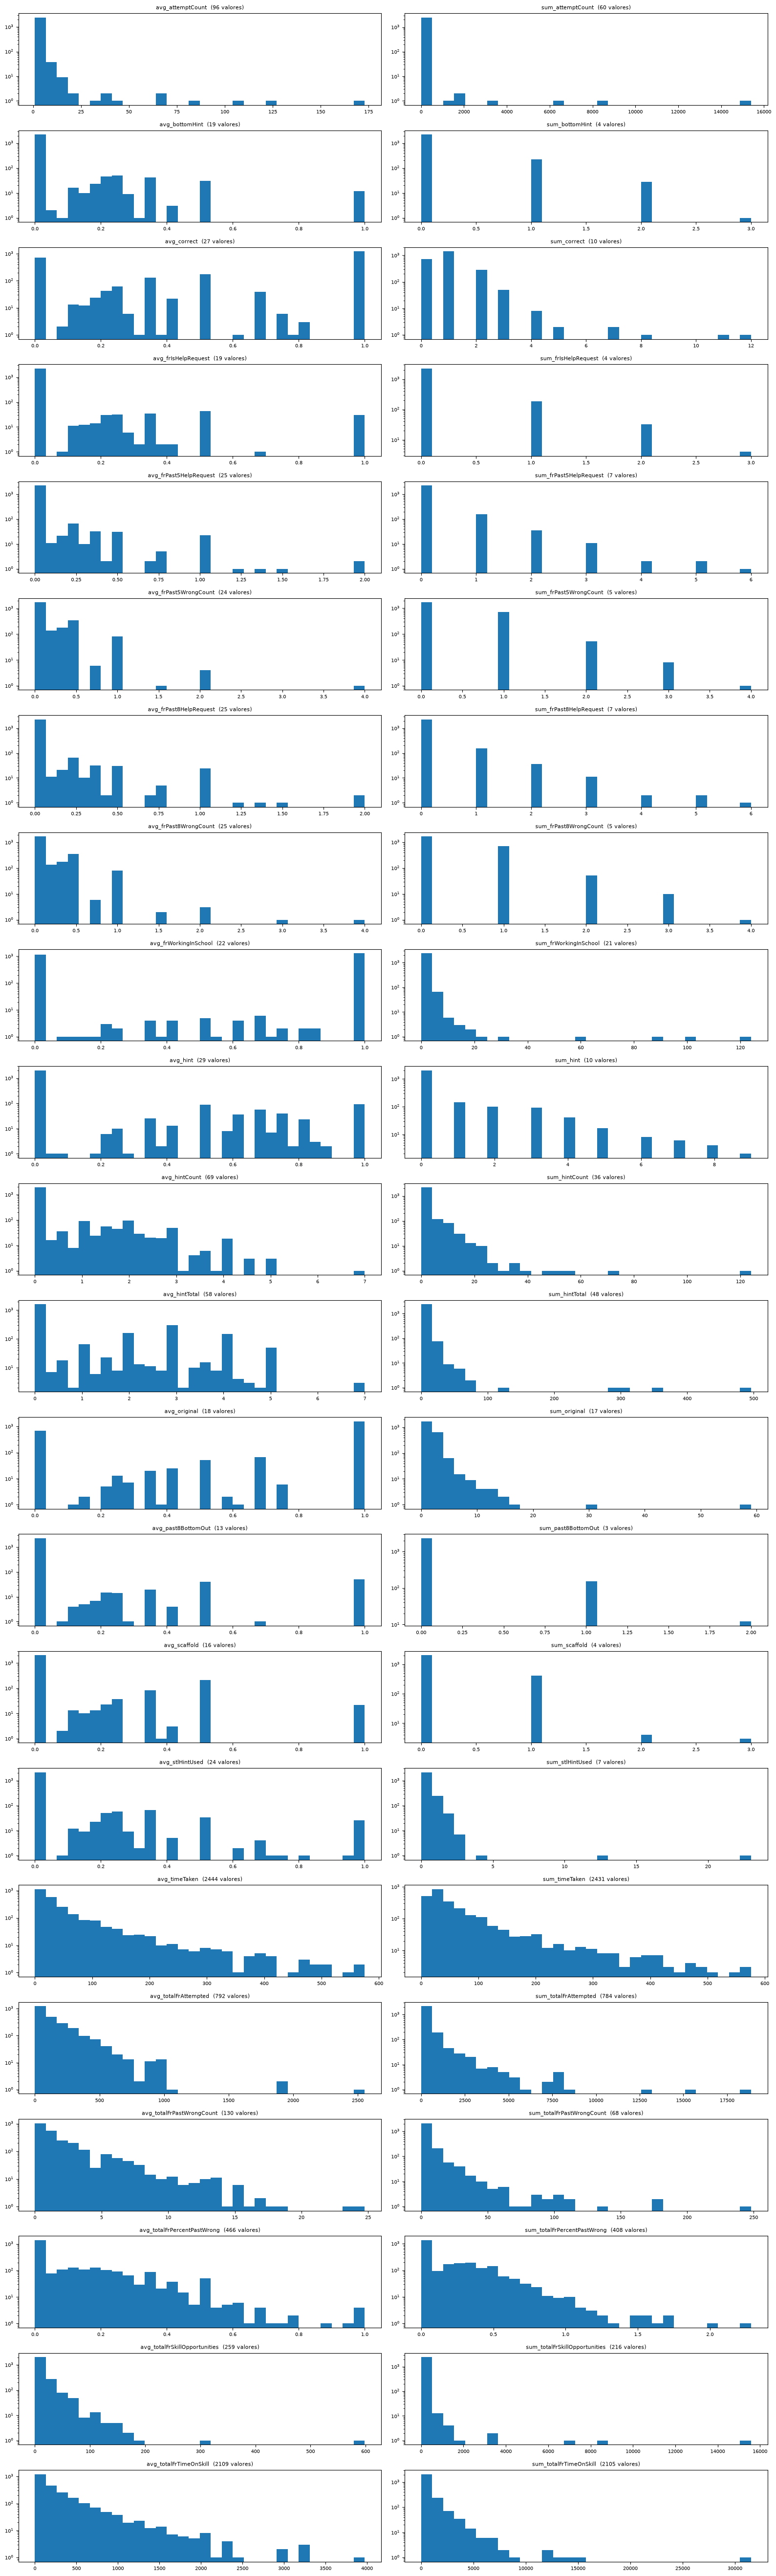

In [13]:
# Vamos a ver cual de avg, max, min, sum, aporta mas info en cada caso para reducir la sobreinformación
# En una primera pasada eliminamos min y max porque no aportan nada nuevo
import matplotlib.pyplot as plt

def hist_features(datos, bases, versiones=("avg", "sum"),
                  bins=30, log_y=True, nombre_png=None):
    fig, ejes = plt.subplots(len(bases), len(versiones), figsize=(16, 2.4 * len(bases)))
    ejes = np.atleast_2d(ejes)
    for i, base in enumerate(bases):
        for j, v in enumerate(versiones):
            ax = ejes[i, j]
            col = f"{v}_{base}"
            if col not in datos.columns:           # por si alguna versión ya se eliminó
                ax.axis("off")
                continue
            ax.hist(datos[col], bins=bins)
            ax.set_title(f"{col}  ({datos[col].nunique()} valores)", fontsize=8)
            ax.tick_params(labelsize=7)
            if log_y:
                ax.set_yscale("log")
    plt.tight_layout()
    if nombre_png:
        plt.savefig(nombre_png, dpi=80, bbox_inches="tight")
    plt.show()

# Las variables base se sacan solas de las columnas de X_train
prefijos = ("avg_", "sum_")
bases = sorted({c.split("_", 1)[1] for c in X_train.columns if c.startswith(prefijos)})
print(len(bases), "variables base:", bases)

# Una sola imagen con todas
hist_features(X_train, bases)

In [14]:
# Aplicaremos log a aquellas features con colas largas mayores a 20
logaritmicas = X_train.columns[X_train.max() > 20].tolist()
print(len(logaritmicas), logaritmicas)

29 ['avg_attemptCount', 'avg_timeTaken', 'avg_totalFrAttempted', 'avg_totalFrPastWrongCount', 'avg_totalFrSkillOpportunities', 'avg_totalFrTimeOnSkill', 'max_attemptCount', 'max_timeTaken', 'max_totalFrAttempted', 'max_totalFrPastWrongCount', 'max_totalFrSkillOpportunities', 'max_totalFrTimeOnSkill', 'min_attemptCount', 'min_timeTaken', 'min_totalFrAttempted', 'min_totalFrPastWrongCount', 'min_totalFrSkillOpportunities', 'min_totalFrTimeOnSkill', 'sum_attemptCount', 'sum_frWorkingInSchool', 'sum_hintCount', 'sum_hintTotal', 'sum_original', 'sum_stlHintUsed', 'sum_timeTaken', 'sum_totalFrAttempted', 'sum_totalFrPastWrongCount', 'sum_totalFrSkillOpportunities', 'sum_totalFrTimeOnSkill']


In [15]:
# Seleccionamso en que casos usaremos solo avg y en cuales tambiés con sum
ambas = ["correct", "attemptCount", "hint", "hintCount", "hintTotal", "bottomHint",
         "past8BottomOut", "stlHintUsed", "frIsHelpRequest",
         "frPast8HelpRequest", "scaffold", "frWorkingInSchool"]
solo_avg = ["timeTaken", "totalFrTimeOnSkill", "frPast8WrongCount",
            "totalFrAttempted", "totalFrSkillOpportunities", "totalFrPastWrongCount",
            "totalFrPercentPastWrong", "original"]
cols_reducida = [f"avg_{v}" for v in ambas + solo_avg] + [f"sum_{v}" for v in ambas]
print(len(cols_reducida), [c for c in cols_reducida if c not in X_train.columns])   

32 []


In [16]:
cols_modelo = cols_reducida + ["urbanicity"]
X_train_red = X_train[cols_modelo]
X_test_red  = X_test[cols_modelo]

#Las cols a tratar en el preprocesamiento
cols_log= [c for c in cols_reducida if X_train_red[c].max() > 20] 
cols_cat = ["urbanicity"] 
cols_num = [c for c in cols_reducida if c not in cols_log] 


In [17]:
X_train_red.describe().T

,count,mean,std,min,25%,50%,75%,max
avg_correct,2474.0,0.575096,0.444704,0.000,0.000000,0.666667,1.000000,1.0000
avg_attemptCount,2474.0,2.125594,5.776638,1.000,1.000000,1.000000,2.000000,173.0000
avg_hint,2474.0,0.112079,0.266069,0.000,0.000000,0.000000,0.000000,1.0000
avg_hintCount,2474.0,0.390424,0.869590,0.000,0.000000,0.000000,0.000000,7.0000
avg_hintTotal,2474.0,0.993453,1.504447,0.000,0.000000,0.000000,2.000000,7.0000
avg_bottomHint,2474.0,0.030290,0.109356,0.000,0.000000,0.000000,0.000000,1.0000
avg_past8BottomOut,2474.0,0.036048,0.159627,0.000,0.000000,0.000000,0.000000,1.0000
avg_stlHintUsed,2474.0,0.044196,0.143268,0.000,0.000000,0.000000,0.000000,1.0000
avg_frIsHelpRequest,2474.0,0.035251,0.138306,0.000,0.000000,0.000000,0.000000,1.0000
avg_frPast8HelpRequest,2474.0,0.034853,0.148778,0.000,0.000000,0.000000,0.000000,2.0000


Definitivamente, nos disponemos a diseñar el pipeline en el que 
1. Preprocesaremos (2 preprocesadores dependiendo de las necesidades del modelo)
    - Aplicaremos logs a cols_log (cuando necesario)
    - Aplicaremos standard scaler a todas (cuando necesario)
    - Aplicaremos onehotencoder a urbanicity
    - Mapearemos el target para convertirlo en binario (concentrado(1)/no concentrado(0))
2. Probaremos modelos
    - Regresión logística (necesita escalado)
    - Random forest
    - Lightgbm


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

#------PREPROCESAMIENTO PARA REG.LOGÍSTICA-------------
pipeline_log_scal = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
]).set_output(transform="pandas")

pipeline_cat= Pipeline([
    ("onehot", OneHotEncoder( sparse_output=False, handle_unknown="ignore"))
])

pipeline_scal = Pipeline([("scaler", StandardScaler())])

prep_rl = ColumnTransformer(
    [
        ("log_scal", pipeline_log_scal, cols_log),          # grupo A
        ("num",      pipeline_scal,      cols_num),         # grupo B
        ("cat",      pipeline_cat,      cols_cat),    # grupo C
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")


In [19]:
X_train_prep_rl = prep_rl.fit_transform(X_train_red)
print(X_train_prep_rl.shape)
print("nulos:", X_train_prep_rl.isna().sum().sum())
print(X_train_prep_rl[cols_log + cols_num].mean().abs().max().round(6)) 

(2474, 35)
nulos: 0
0.0


In [20]:
#-----------PREPROCESAMIENTO ÁRBOLES---------------
prep_arbol = ColumnTransformer(
    [
        ("num", "passthrough", cols_log + cols_num),   
        ("cat", pipeline_cat, cols_cat)            
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

X_train_prep_arbol = prep_arbol.fit_transform(X_train_red)
print(X_train_prep_arbol.shape, "| nulos:", X_train_prep_arbol.isna().sum().sum())
print(X_train_prep_arbol[cols_num].equals(X_train_red[cols_num]))

(2474, 35) | nulos: 0
True


In [21]:
#%pip install lightgbm

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

modelos = {
    "Logistic Regression": (prep_rl, LogisticRegression(max_iter=10000, random_state=42)),
    "Random Forest": (prep_arbol, RandomForestClassifier(random_state=42)),
    "LightGBM": (prep_arbol, LGBMClassifier(random_state=42, verbose=-1))
}

# Nuevo mapeo de la columna target para convertirla en binaria (concentrado 1/ no concentrado 0)
mapa_target = {
    "concentración": 1,
    "concentration": 1,
    "boredom": 0,
    "frustration": 0,
    "confusion": 0,
}

y_train_bin = y_train.map(mapa_target)

metricas_cv = {}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for nombre, (prep, modelo) in modelos.items():
    pipe = Pipeline([("prep", prep), ("modelo", modelo)])
    metricas_cv[nombre] = cross_val_score(pipe, X_train_red, y_train_bin, groups=g_train,
                                          cv=cv, scoring="f1_macro", n_jobs=-1).mean()

pd.Series(metricas_cv).sort_values(ascending=False) 

LightGBM               0.661414
Random Forest          0.659485
Logistic Regression    0.637010
dtype: float64

In [23]:

from sklearn.metrics import make_scorer, f1_score, classification_report

#---------------OPTIMIZACIÓN DE PARAMS-------------------
pipe = Pipeline([
    ("prep", prep_rl),                 # valor inicial: el grid lo cambia
    ("modelo", LogisticRegression())
])

param_grid = [
    {
        "prep":   [prep_rl],
        "modelo": [LogisticRegression(max_iter=10000, random_state=42)],
        "modelo__C": [0.01, 0.1, 1, 10],
        "modelo__class_weight": [None, "balanced"],
    },
    {
        "prep":   [prep_arbol],
        "modelo": [RandomForestClassifier(random_state=42, n_jobs=1)],
        "modelo__n_estimators": [200, 500],
        "modelo__max_depth": [None, 4, 6, 8],
        "modelo__min_samples_leaf": [5, 10, 15, 20],
        "modelo__class_weight": [None, "balanced","balanced_subsample"],
    },
    {
        "prep":   [prep_arbol],
        "modelo": [LGBMClassifier(random_state=42, verbose=-1, n_jobs=1)],
        "modelo__n_estimators": [100, 250],
        "modelo__learning_rate": [0.05, 0.1],
        "modelo__max_depth": [3, 6],
        "modelo__reg_lambda": [0, 5],
        "modelo__min_child_samples": [10, 20],
        "modelo__class_weight": [None, "balanced"],
    },
]

scoring = {"roc_auc": "roc_auc",
           "f1_macro": "f1_macro",
           "balanced_acc": "balanced_accuracy"}

# scoring = {"f1_raras": f1_raras, "roc_auc_ovr": "roc_auc_ovr", "f1_macro": "f1_macro"}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring=scoring,
                    refit="f1_macro", n_jobs=-1)
grid.fit(X_train_red, y_train_bin, groups=g_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [LogisticRegre...ndom_state=42)], 'modelo__C': [0.01, 0.1, ...], 'modelo__class_weight': [None, 'balanced'], 'prep': [ColumnTransfo...mes_out=False)]}, {'modelo': [RandomForestC...ndom_state=42)], 'modelo__class_weight': [None, 'balanced', ...], 'modelo__max_depth': [None, 4, ...], 'modelo__min_samples_leaf': [5, 10, ...], ...}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'balanced_acc': 'balanced_accuracy', 'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold`

In [24]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

print(type(grid.best_params_["modelo"]).__name__)  #Confirma que es Random Classifier
                                

pred_train = cross_val_predict(clone(grid.best_estimator_), X_train_red, y_train_bin,
                         groups=g_train, cv=cv, n_jobs=-1)

print(classification_report(y_train_bin, pred_train, target_names=["no_concentracion", "concentracion"], zero_division=0))

RandomForestClassifier
                  precision    recall  f1-score   support

no_concentracion       0.46      0.59      0.52       433
   concentracion       0.91      0.85      0.88      2041

        accuracy                           0.81      2474
       macro avg       0.69      0.72      0.70      2474
    weighted avg       0.83      0.81      0.82      2474



In [25]:
from sklearn.metrics import roc_auc_score
proba = cross_val_predict(clone(grid.best_estimator_), X_train_red, y_train_bin,
                          groups=g_train, cv=cv, method="predict_proba", n_jobs=-1)

print(proba.shape) 
print("AUC validación:", round(roc_auc_score((y_train_bin == 0).astype(int), proba[:, 0]), 3))
print("F1 macro validación:", round(f1_score(y_train_bin, pred_train, average="macro"), 3))

(2474, 2)
AUC validación: 0.794
F1 macro validación: 0.699


In [26]:
grid.best_params_

{'modelo': RandomForestClassifier(n_jobs=1, random_state=42),
 'modelo__class_weight': 'balanced_subsample',
 'modelo__max_depth': None,
 'modelo__min_samples_leaf': 5,
 'modelo__n_estimators': 500,
 'prep': ColumnTransformer(transformers=[('num', 'passthrough',
                                  ['avg_attemptCount', 'avg_timeTaken',
                                   'avg_totalFrTimeOnSkill',
                                   'avg_totalFrAttempted',
                                   'avg_totalFrSkillOpportunities',
                                   'avg_totalFrPastWrongCount',
                                   'sum_attemptCount', 'sum_hintCount',
                                   'sum_hintTotal', 'sum_stlHintUsed',
                                   'sum_frWorkingInSchool', 'avg_correct',
                                   'avg_hint', 'avg_hintCount', 'avg_hintTotal',
                                   'av...
                                   'avg_frPast8HelpRequest', 'avg_scaffo

In [27]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_train_bin, pred_train))

[[ 255  178]
 [ 296 1745]]


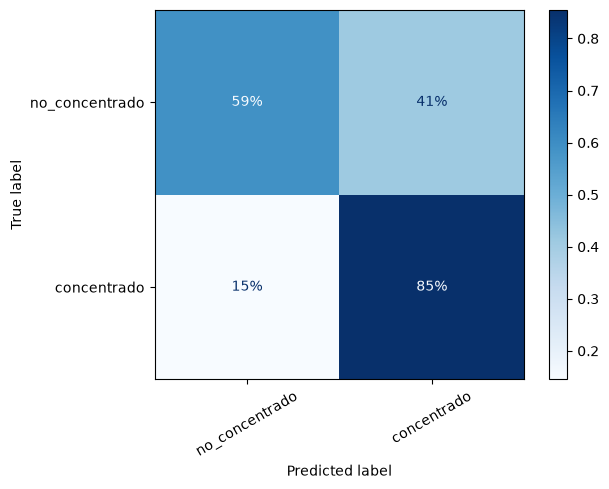

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
disp=ConfusionMatrixDisplay.from_predictions(
    y_train_bin, pred_train,
    display_labels=["no_concentrado", "concentrado"],
    normalize="true", values_format=".0%",
    cmap="Blues", xticks_rotation=30)
plt.show()
disp.figure_.savefig("../imgs/matriz_confusion_val_bin.png", dpi=300, bbox_inches="tight")

In [29]:
from sklearn.inspection import permutation_importance

r = permutation_importance(grid.best_estimator_, X_train_red, y_train_bin, scoring="f1_macro",
                           n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_train_red.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

urbanicity                       0.1851
avg_timeTaken                    0.0575
avg_totalFrAttempted             0.0502
avg_correct                      0.0404
avg_totalFrTimeOnSkill           0.0359
sum_correct                      0.0349
avg_totalFrSkillOpportunities    0.0276
sum_attemptCount                 0.0243
avg_attemptCount                 0.0212
avg_totalFrPastWrongCount        0.0205
dtype: float64


In [30]:
#---------GUARDADO DEL MEJOR MODELO----------------
import joblib
import os

dir_modelos = "..\modelos"
joblib.dump(grid.best_estimator_, os.path.join(dir_modelos, "final_model_binario.pkl"))

<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
C:\Users\TB Val 03\AppData\Local\Temp\ipykernel_27264\4237548174.py:5: SyntaxWarning: invalid escape sequence '\m'
  dir_modelos = "..\modelos"


['..\\modelos\\final_model_binario.pkl']

In [31]:
# --------------------- FASE DE PREDICCIÓN--------------------------

from sklearn.metrics import roc_auc_score

mejor = grid.best_estimator_           # ya reentrenado con todo X_train_red

y_test_bin = y_test.map(mapa_target)
pred_test  = mejor.predict(X_test_red)
proba_test = mejor.predict_proba(X_test_red)

print(classification_report(y_test_bin, pred_test, target_names=["no_concentrado", "concentrado"], zero_division=0))
print("f1_macro   :", round(f1_score(y_test_bin, pred_test, average="macro"), 3))

                precision    recall  f1-score   support

no_concentrado       0.37      0.48      0.42       108
   concentrado       0.88      0.83      0.86       511

      accuracy                           0.77       619
     macro avg       0.63      0.66      0.64       619
  weighted avg       0.79      0.77      0.78       619

f1_macro   : 0.638


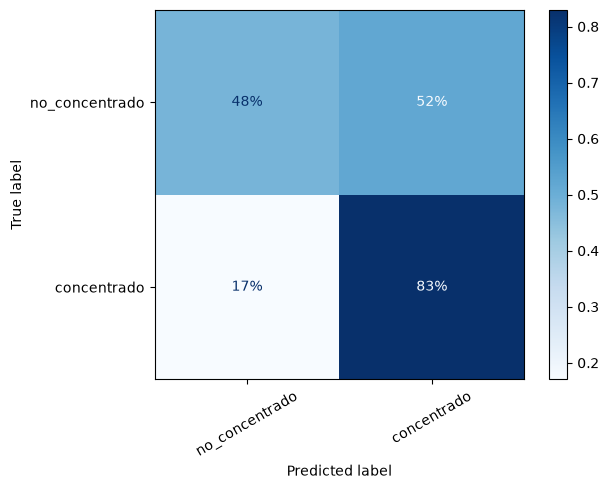

In [32]:
disp2=ConfusionMatrixDisplay.from_predictions(
    y_test_bin, pred_test,
    display_labels=["no_concentrado", "concentrado"],
    normalize="true", values_format=".0%",
    cmap="Blues", xticks_rotation=30)
plt.show()
disp2.figure_.savefig("../imgs/matriz_confusion_test_bin.png", dpi=300, bbox_inches="tight")

In [33]:
from sklearn.metrics import get_scorer

if isinstance(grid.scoring, dict):
    for name, scorer in grid.scoring.items():
        scorer_fn = get_scorer(scorer) if isinstance(scorer, str) else scorer
        score_test = scorer_fn(grid.best_estimator_, X_test_red, y_test_bin)
        print(f"Test {name}: {score_test:.4f}")
elif isinstance(grid.scoring, str):
    scorer_fn = get_scorer(grid.scoring)
    print(f"Test {grid.scoring}: {scorer_fn(grid.best_estimator_, X_test_red, y_test_bin):.4f}")

Test roc_auc: 0.7963
Test f1_macro: 0.6384
Test balanced_acc: 0.6556


In [34]:
traducciones_vars = {
    "urbanicity_1": "Entorno urbano",
    "urbanicity_2": "Entorno suburbano",
    "urbanicity_3": "Entorno rural",

# Aciertos e intentos
    "avg_correct": "Media de respuestas correctas",
    "sum_correct": "Total de respuestas correctas",
    "avg_attemptCount": "Media de intentos por problema",
    "sum_attemptCount": "Total de intentos",

    # Ayudas y pistas
    "avg_hint": "Media de problemas en los que pidió pista",
    "sum_hint": "Total de problemas en los que pidió pista",
    "avg_hintCount": "Media de pistas pedidas",
    "sum_hintCount": "Total de pistas pedidas",
    "avg_hintTotal": "Media de pistas disponibles",
    "sum_hintTotal": "Total de pistas disponibles",
    "avg_bottomHint": "Media de veces que llegó a la última pista",
    "sum_bottomHint": "Total de veces que llegó a la última pista",
    "avg_past8BottomOut": "Media de veces en última pista (últimos 8 prob.)",
    "sum_past8BottomOut": "Total de veces en última pista (últimos 8 prob.)",
    "avg_stlHintUsed": "Media de penúltima pista usada",
    "sum_stlHintUsed": "Total de penúltima pista usada",
    "avg_frIsHelpRequest": "Media de 1ª respuesta pidiendo ayuda",
    "sum_frIsHelpRequest": "Total de 1ª respuesta pidiendo ayuda",
    "avg_frPast8HelpRequest": "Media de ayuda como 1ª resp. (últimos 8 ej.)",
    "sum_frPast8HelpRequest": "Total de ayuda como 1ª resp. (últimos 8 ej.)",

    # Errores recientes
    "avg_frPast8WrongCount": "Media de resp. incorrectas (últimos 8 prob.)",

    # Tiempo
    "avg_timeTaken": "Tiempo medio por problema",
    "avg_totalFrTimeOnSkill": "Tiempo medio acumulado en la habilidad",

    # Historia acumulada
    "avg_totalFrAttempted": "Media de respuestas dadas hasta ahora",
    "avg_totalFrSkillOpportunities": "Media de veces que practicó la habilidad",
    "avg_totalFrPastWrongCount": "Media de errores acumulados hasta ahora",
    "avg_totalFrPercentPastWrong": "Porcentaje medio de errores acumulados",

    # Contexto de tarea
    "avg_original": "Media de problemas principales (no subpasos)",
    "avg_scaffold": "Media de pasos internos del problema",
    "sum_scaffold": "Total de pasos internos del problema",
    "avg_frWorkingInSchool": "Media trabajando en horario escolar",
    "sum_frWorkingInSchool": "Total trabajando en horario escolar",
}

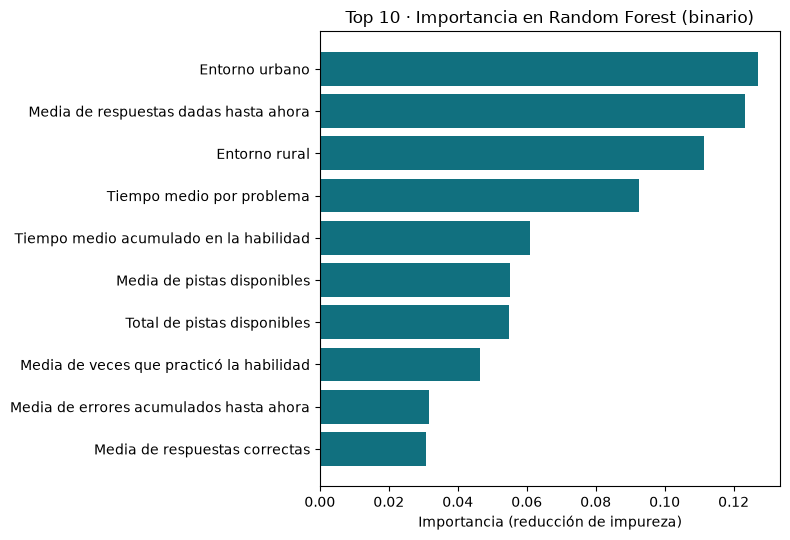

In [36]:


nombres = grid.best_estimator_.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(
    grid.best_estimator_.named_steps["modelo"].feature_importances_,
    index=nombres,
)

top = importancias.sort_values(ascending=False).head(10).iloc[::-1]
etiquetas = [traducciones_vars.get(v, v) for v in top.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(etiquetas, top.values, color="#11707F")
ax.set_title("Top 10 · Importancia en Random Forest (binario)")
ax.set_xlabel("Importancia (reducción de impureza)")

plt.tight_layout()
fig.savefig("../imgs/imp_caracts_binario.png", dpi=300, bbox_inches="tight")
plt.show()